# Olist: late delivery and review scores

## Goal
How do review scores differ between orders delivered late and orders delivered on time? Define "late", bring the reviews table to one row per order, then compare the two groups.

## Setup
Load orders and reviews and parse the timestamps (failures become NaT instead of being dropped silently).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Project folder = the nearest parent that contains data/raw
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
DATA_DIR = ROOT / "data" / "raw"

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
orders["delivered_ts"] = pd.to_datetime(orders["order_delivered_customer_date"], errors="coerce")
orders["estimated_ts"] = pd.to_datetime(orders["order_estimated_delivery_date"], errors="coerce")

reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")
reviews["review_creation_ts"] = pd.to_datetime(reviews["review_creation_date"], errors="coerce")
reviews["review_answer_ts"] = pd.to_datetime(reviews["review_answer_timestamp"], errors="coerce")

print("orders:", orders.shape)
print("reviews:", reviews.shape)

orders: (99441, 10)
reviews: (99224, 9)


## 1. Defining "late"
- **Orders in scope**: `order_status == "delivered"` with an actual delivery timestamp. An order that has not arrived cannot be classed as late or on time. That leaves 96,470 orders.
- **Missing timestamps**: not imputed; affected orders are excluded and counted. `estimated_ts` is never missing. `delivered_ts` is missing for 2,965 orders: 2,957 are not in status delivered, and 8 are marked delivered without a timestamp. Another 6 canceled orders do have a delivery timestamp and are excluded because of their status. Check: 96,470 + 2,971 = 99,441.
- **Late**: the estimated delivery column is always at 00:00:00, so it carries a date and no time of day. Comparing timestamps would class an order estimated for 5 October and delivered at 3 pm on 5 October as late. The actual delivery is therefore reduced to its date, and an order is late only when the actual date is after the estimated date.
- This choice matters: 6,534 orders are late when comparing dates and 7,826 when comparing timestamps. The 1,292 extra orders are exactly those delivered on the estimated day.
- **Late rate**: 6,534 late orders out of 96,470 in scope, about 6.8%.

"Late" compares actual with estimated delivery. It is a different measure from the delivery time in [05-delivery-time](05-delivery-time.ipynb).

In [2]:
# Status distribution
print(orders["order_status"].value_counts())

# Missing values in the two timestamp columns
print("Missing delivered_ts:", orders["delivered_ts"].isna().sum())
print("Missing estimated_ts:", orders["estimated_ts"].isna().sum())

# Status delivered or not, against delivery timestamp present or not
print(pd.crosstab(orders["order_status"] == "delivered", orders["delivered_ts"].notna()))

# Time-of-day part of the estimated delivery: always 00:00:00, so it is a date only
print(orders["estimated_ts"].dt.time.value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Missing delivered_ts: 2965
Missing estimated_ts: 0
delivered_ts  False  True 
order_status              
False          2957      6
True              8  96470
estimated_ts
00:00:00    99441
Name: count, dtype: int64


In [3]:
# In scope: status delivered with a delivery timestamp
kept = orders[(orders["order_status"] == "delivered") & orders["delivered_ts"].notna()].copy()

# Compare by date: drop the time of day from the actual delivery, then compare with the estimated date
kept["is_late"] = kept["delivered_ts"].dt.normalize() > kept["estimated_ts"]

print("In scope:", len(kept))
print("Excluded:", len(orders) - len(kept))
print("Late orders:", kept["is_late"].sum())
print("Late rate:", round(kept["is_late"].mean(), 4))

assert len(kept) + (len(orders) - len(kept)) == 99441
assert kept["order_id"].is_unique

In scope: 96470
Excluded: 2971
Late orders: 6534
Late rate: 0.0677


## 2. Checking the reviews table
- Are `review_id` and `order_id` unique? How many reviews can one order have?
- Are `review_score` or the review timestamps ever missing?
- How many orders have no review? Do any reviews point to an order that does not exist?
- **Rule for several reviews on one order**: keep the latest one (sort by review time, keep the last row), as the customer's final opinion. Only 547 orders have more than one review, under 1% of orders, and 202 of them have differing scores, so another rule would change the result very little.

In [4]:
# 1. Duplicates
print("Rows:", len(reviews))
print("Duplicate review_id:", reviews["review_id"].duplicated().sum())
print("Duplicate order_id:", reviews["order_id"].duplicated().sum())

# Reviews per order
reviews_per_order = reviews.groupby("order_id").size()
print("Most reviews on one order:", reviews_per_order.max())
print(reviews_per_order.value_counts())

# 2. Missing values
print(reviews[["review_score", "review_creation_ts", "review_answer_ts"]].isna().sum())

# 3. Matching
print("Orders without a review:", (~orders["order_id"].isin(reviews["order_id"])).sum())
print("Reviews without a matching order:", (~reviews["order_id"].isin(orders["order_id"])).sum())

Rows: 99224
Duplicate review_id: 814
Duplicate order_id: 551
Most reviews on one order: 3
1    98126
2      543
3        4
Name: count, dtype: int64
review_score          0
review_creation_ts    0
review_answer_ts      0
dtype: int64
Orders without a review: 768
Reviews without a matching order: 0


In [5]:
# One row per order: sort by review time, keep the last row for each order_id
review_per_order = (
    reviews.sort_values(["review_creation_ts", "review_answer_ts"])
           .drop_duplicates(subset="order_id", keep="last")
)

print("Rows after deduplication:", len(review_per_order))

# One row per order, and no order lost
assert review_per_order["order_id"].is_unique
assert len(review_per_order) == reviews["order_id"].nunique()

Rows after deduplication: 98673


## 3. Comparing the two groups
**Low score**: a score of 2 or less. Scores of 1 and 2 are clearly dissatisfied; 3 is treated as neutral.

The orders in scope are joined to the one-row-per-order reviews and split by `is_late`: number of orders, orders with a review, mean score, and share of low scores.

In [6]:
merged = kept.merge(review_per_order[["order_id", "review_score"]], on="order_id", how="left")

# The join must not add rows
print(len(merged), merged["order_id"].is_unique)
print(merged[["order_id", "is_late", "review_score"]].head(3))

# Low score: 2 or less
merged["low_score"] = merged["review_score"] <= 2

# Reviewed orders only: the denominator of the low-score share
reviewed = merged[merged["review_score"].notna()]

summary = merged.groupby("is_late").agg(
    n_orders=("order_id", "count"),
    n_reviewed=("review_score", "count"),
    avg_score=("review_score", "mean"),
)
summary["low_share"] = reviewed.groupby("is_late")["low_score"].mean()

print(summary.round(3))

96470 True
                           order_id  is_late  review_score
0  e481f51cbdc54678b7cc49136f2d6af7    False           4.0
1  53cdb2fc8bc7dce0b6741e2150273451    False           4.0
2  47770eb9100c2d0c44946d9cf07ec65d    False           5.0


         n_orders  n_reviewed  avg_score  low_share
is_late                                            
False       89936       89443      4.290      0.093
True         6534        6381      2.271      0.624


## Checks
- **In scope + excluded = 99,441, with every excluded group counted.** In scope 96,470, excluded 2,971. The excluded orders are: canceled 625, unavailable 609, past the estimated date with no delivery record 1,729, and delivered without a delivery timestamp 8 (625 + 609 + 1,729 + 8 = 2,971).
- **Reviews are reduced to one row per order before the join, and the join adds no orders.** Reviews go from 99,224 rows to 98,673; after the join the output is `96470 True`.
- **The mean score is over reviewed orders, not all orders.** Orders without a review have a missing score, which `mean` skips: 4.29 for on-time orders is the mean of 89,443 reviewed orders (not 89,936), and 2.27 for late orders is the mean of 6,381 (not 6,534). The low-score share uses the same reviewed orders. An order without a review must not be flagged `False` for `low_score` and left in the denominator, which would understate the share.
- **The conclusion is stated as an association.** See the limits below.

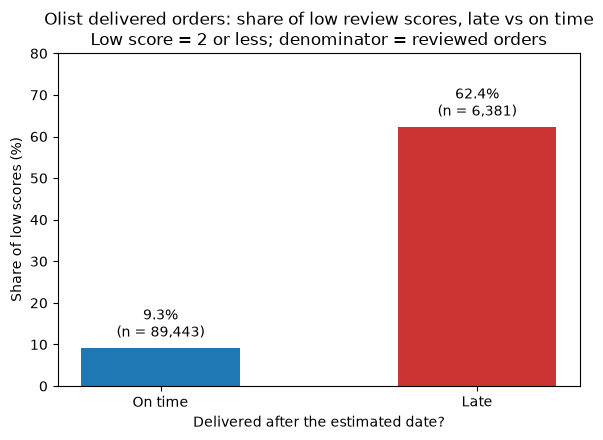

In [7]:
import matplotlib.pyplot as plt

labels = ["On time", "Late"]                     # the False and True rows of summary
shares = summary["low_share"] * 100
counts = summary["n_reviewed"]

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(labels, shares, color=["#1f77b4", "#cc3333"], width=0.5)

# Share and sample size on each bar
for bar, share, n in zip(bars, shares, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, share + 1.5,
            f"{share:.1f}%\n(n = {n:,})", ha="center", va="bottom")

ax.set_title("Olist delivered orders: share of low review scores, late vs on time\nLow score = 2 or less; denominator = reviewed orders")
ax.set_xlabel("Delivered after the estimated date?")
ax.set_ylabel("Share of low scores (%)")
ax.set_ylim(0, 80)
plt.tight_layout()
plt.show()

## Findings
**Result.** Of 96,470 delivered orders, the 6,534 delivered late (actual date after the estimated date) have a mean review score of 2.27, and 62.4% of them received a low score (2 or less). The 89,936 delivered on time have a mean of 4.29 and a low-score share of 9.3%. Late delivery and low scores are strongly associated.

**Definitions.** Scores cover reviewed orders only (6,381 late, 89,443 on time). When an order has several reviews the latest is used.

**Limits.**
- This compares two groups of orders. It shows that late delivery and low scores occur together, not that lateness causes the low scores: late orders may share other problems (stock-outs, slow dispatch by the seller, remote destinations) that are not controlled for here.
- Another 1,729 orders had passed their estimated date without any delivery record. They are not in the 6.8% late rate or in this comparison.